In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [1]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi
import matplotlib

/home/wx2203/anaconda3/lib/python3.7/site-packages/pandas/compat/_optional.py:138: UserWarning: Pandas requires version '2.7.0' or newer of 'numexpr' (version '2.6.9' currently installed).
  warnings.warn(msg, UserWarning)
/home/wx2203/anaconda3/lib/python3.7/site-packages/dask/config.py:168: YAMLLoadWarning: calling yaml.load() without Loader=... is deprecated, as the default Loader is unsafe. Please read https://msg.pyyaml.org/load for full details.
  data = yaml.load(f.read()) or {}


In [2]:
prefix = '/mnt/staging/' # or 
mouse='cm229'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_sensory = str(PREPARES / "index-S1") + "/"
fetch_path_motor = str(PREPARES / "index-M2") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'


path_config = str(PREPARES / "config") + "/"
fetch_path_running = str(PREPARES / "epochs-running") + "/"
fetch_path_rest = str(PREPARES / "epochs-rest") + "/"

figure_config_root = str(PREPARES / "config") + "/"

In [3]:
M2_ind = load_pickle(fetch_path_motor+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_sensory+'brightest_ind_'+mouse)


In [4]:
def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))
    plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
    plt.axis('off')
    plt.colorbar(fraction=0.046, pad=0.04)
    if if_return_map ==True:
        return std_map

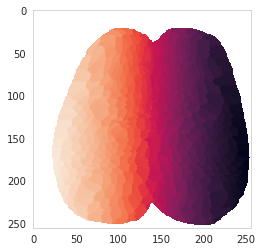

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
plt.imshow(IDX_sorted)


In [6]:
def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))
    plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
    plt.axis('off')
    # plt.colorbar()
    if if_return_map ==True:
        return std_map



In [7]:
S1_ind = sensory_ind['RFP']

In [8]:
all_gathered = ['M_jrgeco',
               'M_day_label','M_ind','M_face_pc','M_body_pc',
                'M_LFP_vel_norm','M_RFP_vel_norm','M_rotf']
dict_collection_mice = {}

all_gathered = load_pickle(fetch_path_running+'run_'+'cm229')

for key in all_gathered:
    try:
        dict_collection_mice[key]=np.squeeze(all_gathered[key])[100-60:100+200,:]
    except:
        try:
            dict_collection_mice[key]=np.squeeze(all_gathered[key])[:]
        except:
            dict_collection_mice[key]=np.squeeze(all_gathered[key])


In [ ]:
# # load full data
# dict_full_jrgeco_mice = load_pickle(fetch_path_running+'dict_full_jrgeco_mice_run')

In [9]:
dict_full_gcamp_mice = {}
dict_full_jrgeco_mice = {}
T_total = 100

# mouse config
M_day_label_here = dict_collection_mice['M_day_label']
M_ind_here = dict_collection_mice['M_ind']
step_1_root_here = step_1_root
ds_factor_here = 4 
dict_full_gcamp_mice['cm229'] = []
dict_full_jrgeco_mice['cm229'] = []
# fetch full data
for i_session, session_id in enumerate(M_day_label_here):
    session_id = session_id.split(' ')[0] # eliminate empty spaces
    day = session_id.split('cm229_')[1].split('_')[0]
    run_id = session_id.split('cm229_')[1].split('_')[1]

    f3 = list(set(glob.glob(step_1_root_here+'cm229'+"/"+day+"/*"+run_id+"*.mat")))[0]
    ind = int(M_ind_here[i_session]/ds_factor_here)
    with h5py.File(f3,'r') as f_H: 
        m = f_H['m']
        C = np.array(f_H['C']['gcamp'])
        S = np.array(f_H['S']['gcamp'])[ind-60:ind+200,:]
        # cut [-60,60] frames slice
        mask = np.array(f_H['mask'])
        # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
        nanidx = np.squeeze(m['nanidx'])==1
        CS = np.dot(S,C).transpose()
        gcamp = np.zeros((len(nanidx),CS.shape[-1]))
        gcamp[:] = np.nan
        gcamp[nanidx==True,:] = CS
        gcamp = gcamp.reshape((256,256,-1)).transpose((1,0,2))
        dict_full_gcamp_mice['cm229'].append(gcamp[:,:,:,np.newaxis])
        
        C = np.array(f_H['C']['jrgeco'])
        S = np.array(f_H['S']['jrgeco'])[ind-60:ind+200,:]
        # cut [-60,60] frames slice
        mask = np.array(f_H['mask'])
        # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
        nanidx = np.squeeze(m['nanidx'])==1
        CS = np.dot(S,C).transpose()
        jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
        jrgeco[:] = np.nan
        jrgeco[nanidx==True,:] = CS
        jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))
        dict_full_jrgeco_mice['cm229'].append(jrgeco[:,:,:,np.newaxis])
        
dict_full_gcamp_mice['cm229']= np.concatenate(dict_full_gcamp_mice['cm229'],axis=3)
dict_full_jrgeco_mice['cm229']= np.concatenate(dict_full_jrgeco_mice['cm229'],axis=3)

In [10]:
# load midline
with h5py.File(figure_config_root+'mask_midline_v2_'+'cm229'+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T
ss = dict_full_jrgeco_mice['cm229'].shape
mask_midline_array = np.repeat(np.repeat(mask_midline[:,:,np.newaxis],
                               repeats=ss[2],axis=2)[:,:,:,np.newaxis],
                               repeats=ss[3],axis=3)
dict_full_jrgeco_mice['cm229'] = np.multiply(dict_full_jrgeco_mice['cm229'],mask_midline_array)
dict_full_gcamp_mice['cm229'] = np.multiply(dict_full_gcamp_mice['cm229'],mask_midline_array)


# spectrogram for S1

In [12]:
def make_spectrogram(mean_of_regions,fs):
    ss = mean_of_regions.shape
    t_ss = ss[0] # time 650
    num_bouts = ss[1] # bouts
    
    # concat 
    # CAUTION: TRANSPOSE HERE IS IMPORTANT
    x = mean_of_regions.transpose().reshape((1,-1))
    # NOW TIME COURSES ARE CONCATED
    long_ss = x.shape[1]
    
    f, t, Sxx = signal.spectrogram(x, fs ,noverlap=18,nperseg=30,nfft=300)
    Sxx = np.squeeze(Sxx)
    num_freq_bins = Sxx.shape[0]
    
    Slinn = np.zeros((num_freq_bins,long_ss))
    for i in range(num_freq_bins):
        Slinn[i,:] = np.interp(np.divide(range(long_ss),fs),t,np.abs(Sxx[i,:]));
    Slinn = Slinn.reshape((num_freq_bins,num_bouts,t_ss))
    return Slinn,f

In [13]:
norm_baseline_value = np.mean(dict_full_jrgeco_mice['cm229'][:,:,:60,:],2)[:,:,np.newaxis,:]
norm_MM_jrgeco  = dict_full_jrgeco_mice['cm229']  - norm_baseline_value

norm_baseline_value = np.mean(dict_full_gcamp_mice['cm229'][:,:,:60,:],2)[:,:,np.newaxis,:]
norm_MM_gcamp  = dict_full_gcamp_mice['cm229']  - norm_baseline_value

norm_M_jrgeco = getH_4D(norm_MM_jrgeco,IDX_sorted)
norm_M_gcamp = getH_4D(norm_MM_gcamp,IDX_sorted)

M_RFP_vel = dict_collection_mice['M_RFP_vel_norm']
norm_baseline_value = np.mean(M_RFP_vel[:60,:],0)[np.newaxis,:]
norm_M_RFP  = M_RFP_vel  - norm_baseline_value


/home/wx2203/Weihao/code_locker/common_functions/f2_utils.py:28: RuntimeWarning: Mean of empty slice
  H[i_H,:,:]=np.nanmean(data_reshape[temp==True,:,:],axis=0)


<AxesSubplot:>

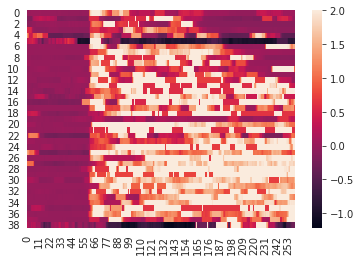

In [14]:
sns.heatmap(norm_M_RFP.T,vmax=2)

In [15]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')
seed_ROI_xy = dict_seed_ROI_xy_mice['cm229']

choice_body_part_dict = {0:'RFP_S1',1:'RFP_M1',2:'RFP_M2'}
choice_dict = {0:sensory_ind['RFP'],1:322,2:[]}
jrgeco2plot ={};gcamp2plot ={};
for i_bdp in range(3):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    if bdp == 'RFP_M2':
        y_top_left = seed_ROI_xy['RFP']['y_top_left']
        y_botton_right = seed_ROI_xy['RFP']['y_botton_right']
        x_top_left =seed_ROI_xy['RFP']['x_top_left']
        x_botton_right=seed_ROI_xy['RFP']['x_botton_right']
        jrgeco2plot[bdp] = np.nanmean(np.nanmean(
    norm_MM_jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
        gcamp2plot[bdp] = np.nanmean(np.nanmean(
    norm_MM_gcamp[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    else:
        jrgeco2plot[bdp]=norm_M_jrgeco[ind,:,:]
        gcamp2plot[bdp]=norm_M_gcamp[ind,:,:]


    

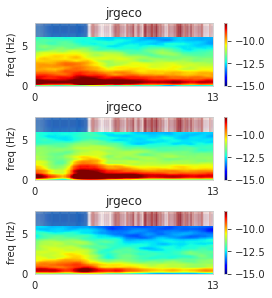

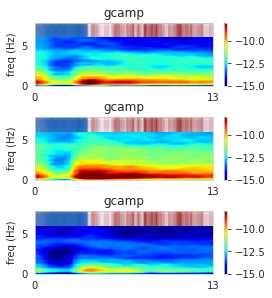

In [16]:
x = range(M_RFP_vel.shape[0])
my_xticks = np.divide(range(M_RFP_vel.shape[0]),15)
y = range(M_RFP_vel.shape[1])
my_yticks = range(M_RFP_vel.shape[1])

dict_slinn,dict_f = {'jrgeco':{},'gcamp':{}},{'jrgeco':{},'gcamp':{}}

for fluorophore in ['jrgeco','gcamp']:
    plt.figure(figsize=(4,15))
    for i_bdp in range(3):
        bdp = choice_body_part_dict[i_bdp]
        ind = choice_dict[i_bdp]
        # params = {"text.color" : colors[i]}
        # plt.rcParams.update(params)
        plt.subplot(9,1,i_bdp+1)

        exec("Slinn,f = make_spectrogram({}2plot[bdp],fs=15)".format(fluorophore))
        dict_slinn[fluorophore][bdp] = Slinn
        dict_f[fluorophore][bdp]=f

    #         plt.pcolormesh(x, f, np.log(np.mean(Slinn,axis=1)),cmap='vlag')
        plt.pcolormesh(x, f, np.log(np.mean(Slinn,axis=1)),cmap='jet',vmin=-15,vmax=-8)
        plt.colorbar()
        plt.xticks(np.array(x[::200],dtype='int'), 
               np.array(my_xticks[::200],dtype='int'));

    #         plt.xticks([]);plt.yticks([])
        plt.ylim([0,7.9])
        plt.xlim([0,200])

        beh2plot = norm_M_RFP
        avg = np.mean(beh2plot,axis=1)
        avg = normalize(avg)
    #         plt.scatter(range(len(avg)),np.ones((len(avg)))*0.11+11.2,marker="|",s=950,c=avg,cmap='magma')
        plt.scatter(range(len(avg)),np.ones((len(avg)))*0.11+8,marker="|",s=1050,c=avg,cmap='vlag')
        plt.title(fluorophore)
        plt.ylabel('freq (Hz)')
        if i_bdp==4:
            plt.xlabel('time (s)')
    plt.subplots_adjust(hspace=0.5)



# spectrogram for behavior

Text(0, 0.5, 'freq (Hz)')

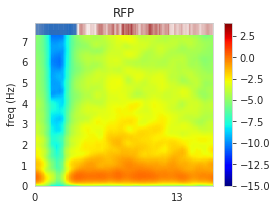

In [17]:
x = range(norm_M_RFP.shape[0])
my_xticks = np.divide(range(norm_M_RFP.shape[0]),15)
y = range(norm_M_RFP.shape[1])
my_yticks = range(norm_M_RFP.shape[1])

dict_slinn_behavior,dict_f_behavior = [],[]

plt.figure(figsize=(4,3))

Slinn,f = make_spectrogram(norm_M_RFP,fs=15)
dict_slinn_behavior = Slinn
dict_f_behavior=f

#         plt.pcolormesh(x, f, np.log(np.mean(Slinn,axis=1)),cmap='vlag')
plt.pcolormesh(x, f, np.log(np.mean(Slinn,axis=1)),cmap='jet',vmin=-15,vmax=4)
plt.colorbar()
plt.xticks(np.array(x[::200],dtype='int'), 
       np.array(my_xticks[::200],dtype='int'));

#         plt.xticks([]);plt.yticks([])
plt.ylim([0,7.9])
plt.xlim([0,250])

beh2plot = norm_M_RFP
avg = np.mean(beh2plot,axis=1)
avg = normalize(avg)
#         plt.scatter(range(len(avg)),np.ones((len(avg)))*0.11+11.2,marker="|",s=950,c=avg,cmap='magma')
plt.scatter(range(len(avg)),np.ones((len(avg)))*0.11+8,marker="|",s=1050,c=avg,cmap='vlag')
plt.title('RFP')
plt.ylabel('freq (Hz)')





# variance map

In [18]:
ss = norm_M_jrgeco.shape
norm_M_jrgeco_std = np.empty((ss[0],ss[1],0))
norm_M_gcamp_std = np.empty((ss[0],ss[1],0))
for i_bout in range(ss[2]):
    # jrgeco
    temp = pd.DataFrame(norm_M_jrgeco[:,:,i_bout]).rolling(15,axis=1).std().values
    norm_M_jrgeco_std=np.append(norm_M_jrgeco_std,temp[:,:,np.newaxis],axis=2)
    # gcamp
    temp = pd.DataFrame(norm_M_gcamp[:,:,i_bout]).rolling(15,axis=1).std().values
    norm_M_gcamp_std=np.append(norm_M_gcamp_std,temp[:,:,np.newaxis],axis=2)

In [19]:
norm_M_jrgeco_std.shape

(500, 260, 39)

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: Mean of empty slice
  """Entry point for launching an IPython kernel.


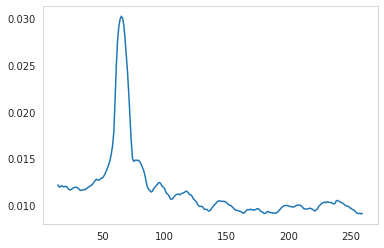

In [20]:
plt.plot(np.nanmean(np.mean(norm_M_jrgeco_std[:,:,:],-1),0))

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:11: RuntimeWarning: Mean of empty slice
  # This is added back by InteractiveShellApp.init_path()


ValueError: x and y must have same first dimension, but have shapes (160,) and (0, 160)

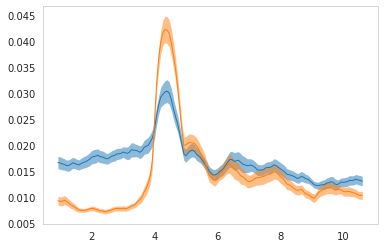

In [87]:
palatte_dict={}
palatte_dict['LM_M1']='#edcc86'
palatte_dict['LM_M2']='#6dae96'
palatte_dict['LM_S1'] = '#f9292a' #palatte_dict['RFP']
t_ax_2show = np.divide(range(norm_M_jrgeco_std.shape[1]),15)
for ii,iroi in enumerate(choice_body_part_dict.keys()):
    ind_roi='RFP'
    bdp_here = choice_body_part_dict[iroi]
    cortex = bdp_here.split('_')[1]
    ind = choice_dict[iroi]
    avg = np.nanmean(norm_M_jrgeco_std[ind,:,:],-1)
    plt.plot(t_ax_2show,avg,label = bdp_here,linewidth=1)
    sem = stats.sem(norm_M_jrgeco_std[ind,:,:],-1)
    plt.fill_between(t_ax_2show,avg - sem,avg + sem,alpha=0.5,linewidth=0)


avg = np.mean(norm_M_RFP[:,:],-1)/40
plt.plot(t_ax_2show,avg,color='tab:blue',label = 'RFP vel',linewidth=1)
sem = stats.sem(norm_M_RFP[:,:],-1)/40
plt.fill_between(t_ax_2show,avg - sem,avg + sem,color='tab:blue',alpha=0.5,linewidth=0)


plt.xlim([0,25])
plt.ylabel('rolling std');plt.xlabel('time (s)')
plt.title('temporal variance during rest')
plt.axvline(t_ax_2show[90]);plt.axvline(t_ax_2show[210])
plt.legend()


In [21]:
trimmed_range = range(60,180)
jrgeco2plot_trimmed = jrgeco2plot.copy()
for key in jrgeco2plot_trimmed.keys():
    jrgeco2plot_trimmed[key] = jrgeco2plot_trimmed[key][trimmed_range,:]
trimmed_dict_slinn = dict_slinn.copy()
for fluorophore in ['jrgeco','gcamp']:
    for bdp in trimmed_dict_slinn[fluorophore].keys():
        trimmed_dict_slinn[fluorophore][bdp] = trimmed_dict_slinn[fluorophore][bdp][:,:,trimmed_range]
        
trimmed_dict_slinn_behavior = dict_slinn_behavior[:,:,trimmed_range]

for key in gcamp2plot.keys():
    gcamp2plot[key]=gcamp2plot[key][trimmed_range,:]
    jrgeco2plot[key]=jrgeco2plot[key][trimmed_range,:]

In [30]:
dict_everything_save = {
'choice_body_part_dict':choice_body_part_dict,
'choice_dict':choice_dict,
'dict_slinn':dict_slinn,
'dict_f':dict_f,
'IDX_sorted':IDX_sorted,
'norm_M_jrgeco':norm_M_jrgeco[:,trimmed_range,:],
'norm_M_gcamp':norm_M_gcamp[:,trimmed_range,:],
'norm_M_RFP':norm_M_RFP[trimmed_range,:],
'norm_M_jrgeco_std':norm_M_jrgeco_std[:,trimmed_range,:],
'norm_M_gcamp_std':norm_M_gcamp_std[:,trimmed_range,:],
'node_coords':node_coords,
'trimmed_range':trimmed_range,
'trimmed_dict_slinn':trimmed_dict_slinn,
'jrgeco2plot_trimmed':jrgeco2plot_trimmed,
'trimmed_dict_slinn_behavior':trimmed_dict_slinn_behavior,
    'gcamp2plot':gcamp2plot,
    'jrgeco2plot':jrgeco2plot,
}
save_root = str(FIGURES / "figureS4") + "/"
save_pickle(dict_everything_save,save_root+'csn-thy1-compare-trimmed-RUN-'+mouse)